# NetSentinel — Clustering Track (Review 2)

**Course**: 23CSE301 Machine Learning Capstone  
**Track**: Clustering — Unsupervised Behavioral Profiling  
**Dataset**: CIC-IDS2017 Network Traffic (same feature space as Classification Track)  
**Objective**: Apply unsupervised clustering algorithms to discover hidden traffic behavioral patterns and anomalous communication structures without using ground-truth labels during model fitting.

### Algorithms
| # | Algorithm | Key Visualisation |
|---|-----------|-------------------|
| 1 | K-Means Clustering | Elbow Curve (Inertia vs. $k$) |
| 2 | Agglomerative Hierarchical Clustering | Dendrogram + Linkage Analysis |

### Evaluation Metrics
- Silhouette Score
- Davies-Bouldin Index
- Calinski-Harabasz Index
- PCA-reduced 2D Scatter Plots
- t-SNE Visualisation

In [1]:
# ── Library Imports ──
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import dendrogram, linkage

# Visualisation settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10
warnings.filterwarnings("ignore")

print("Clustering libraries imported successfully.")

Clustering libraries imported successfully.


## 1. Load Dataset

We load the CIC-IDS2017 network traffic dataset — the same feature space used in the Classification Track. For clustering, the ground-truth `Label` column is **excluded during model fitting** and used **only after clustering** for post-hoc interpretation and validation.

In [2]:
# Load dataset
dataset_path = (
    "../data/classification/network_traffic_classification.csv"
    if os.path.exists("../data/classification/network_traffic_classification.csv")
    else "data/classification/network_traffic_classification.csv"
)

df_raw = pd.read_csv(dataset_path)
print(f"Dataset loaded: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
print(f"Columns: {list(df_raw.columns[:10])} ... [{df_raw.shape[1]} total]")
print(f"\nTarget distribution (ground-truth, NOT used in clustering):")
print(df_raw["Label"].value_counts())

Dataset loaded: 8,000 rows, 79 columns
Columns: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std'] ... [79 total]

Target distribution (ground-truth, NOT used in clustering):
Label
BENIGN                      4859
DoS Hulk                    1552
PortScan                     653
DDoS                         367
DoS GoldenEye                254
FTP-Patator                  130
SSH-Patator                  114
Web Attack – Brute Force      38
Bot                           33
Name: count, dtype: int64


## 2. Dataset Audit

We perform a data quality check for missing values, infinite values, and duplicates before clustering.

In [3]:
# Data Audit
print("=== DATA TYPES ===")
print(df_raw.dtypes.value_counts())

print("\n=== MISSING VALUES ===")
null_cols = df_raw.isnull().sum()
null_cols = null_cols[null_cols > 0]
if len(null_cols) > 0:
    print(null_cols)
else:
    print("No missing values detected.")

print("\n=== INFINITE VALUES ===")
numeric_cols = df_raw.select_dtypes(include=[np.number]).columns
inf_count = np.isinf(df_raw[numeric_cols]).sum().sum()
print(f"Total infinite values: {inf_count}")

print(f"\n=== DUPLICATES ===")
dup_count = df_raw.duplicated().sum()
print(f"Duplicate rows: {dup_count}")
print(f"\nDataset shape: {df_raw.shape}")

=== DATA TYPES ===
float64    48
int64      30
str         1
Name: count, dtype: int64

=== MISSING VALUES ===
Flow Bytes/s      20
Flow Packets/s    20
dtype: int64

=== INFINITE VALUES ===
Total infinite values: 20

=== DUPLICATES ===
Duplicate rows: 0

Dataset shape: (8000, 79)


## 3. Data Cleaning & Preprocessing

### Cleaning Strategy
1. **Drop duplicates** to remove redundant flow records.
2. **Replace infinite values** with NaN, then drop rows with any NaN.
3. **Separate features from labels** — `Label` is stored for post-hoc analysis but excluded from clustering.
4. **Standardise features** using `StandardScaler` (zero mean, unit variance) — essential for distance-based clustering algorithms.

In [4]:
# 1. Drop duplicates
df_clean = df_raw.drop_duplicates().copy()
print(f"After dropping duplicates: {df_clean.shape[0]:,} rows")

# 2. Handle infinite values
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)
df_clean.dropna(inplace=True)
print(f"After dropping inf/NaN rows: {df_clean.shape[0]:,} rows")

# 3. Separate features and ground-truth labels
# Store ground-truth labels for post-hoc validation
ground_truth_labels = df_clean["Label"].copy()
le = LabelEncoder()
ground_truth_encoded = le.fit_transform(ground_truth_labels)
print(f"\nGround-truth classes: {list(le.classes_)}")
print(f"Number of ground-truth classes: {len(le.classes_)}")

# Drop non-numeric and target columns
X_cluster = df_clean.select_dtypes(include=[np.number]).copy()
print(f"\nFeature matrix shape: {X_cluster.shape}")

After dropping duplicates: 8,000 rows
After dropping inf/NaN rows: 7,940 rows

Ground-truth classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'FTP-Patator', 'PortScan', 'SSH-Patator', 'Web Attack – Brute Force']
Number of ground-truth classes: 9

Feature matrix shape: (7940, 78)


In [5]:
# 4. Standardise features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)
print(f"Scaled feature matrix shape: {X_scaled.shape}")
print(f"Mean of first 5 features (should be ~0): {X_scaled[:, :5].mean(axis=0).round(6)}")
print(f"Std of first 5 features (should be ~1):  {X_scaled[:, :5].std(axis=0).round(6)}")

Scaled feature matrix shape: (7940, 78)
Mean of first 5 features (should be ~0): [ 0. -0. -0. -0. -0.]
Std of first 5 features (should be ~1):  [1. 1. 1. 1. 1.]


## 4. Exploratory Data Analysis — Dimensionality Assessment

Before clustering, we assess the intrinsic dimensionality of the data using PCA to understand how many components capture most of the variance.

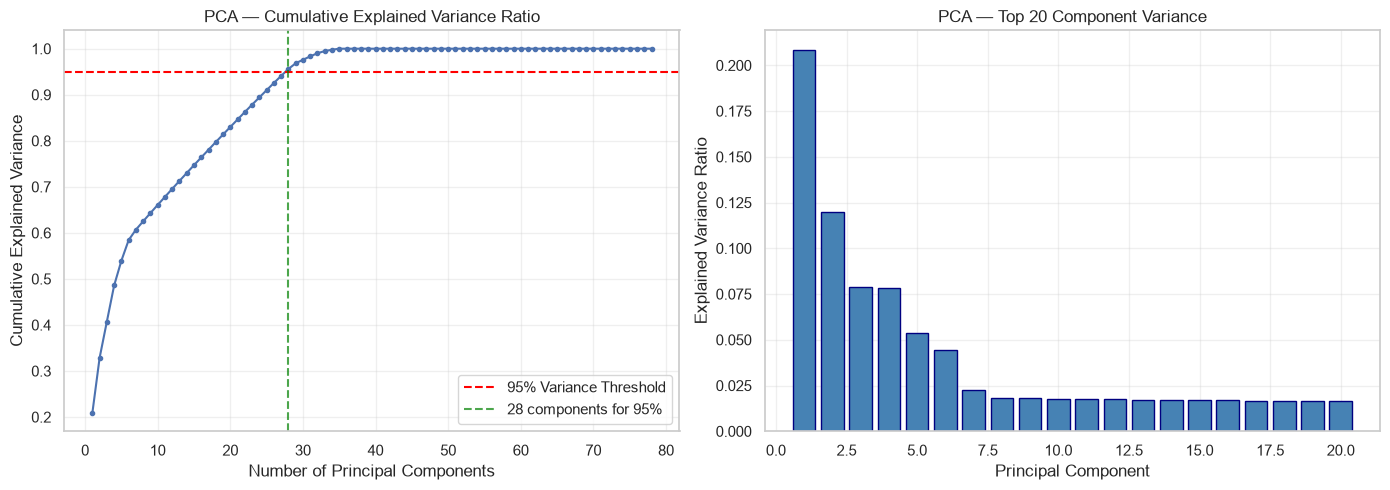

Components needed for 95% variance: 28
Components needed for 99% variance: 32


In [6]:
# PCA Variance Analysis
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

cumulative_var = np.cumsum(pca_full.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Cumulative Explained Variance
axes[0].plot(range(1, len(cumulative_var) + 1), cumulative_var, "b-o", markersize=3)
axes[0].axhline(y=0.95, color="red", linestyle="--", label="95% Variance Threshold")
axes[0].set_xlabel("Number of Principal Components")
axes[0].set_ylabel("Cumulative Explained Variance")
axes[0].set_title("PCA — Cumulative Explained Variance Ratio")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

n_95 = np.argmax(cumulative_var >= 0.95) + 1
axes[0].axvline(x=n_95, color="green", linestyle="--", alpha=0.7, label=f"{n_95} components for 95%")
axes[0].legend()

# Plot 2: Individual Component Variance (Top 20)
top_n = min(20, len(pca_full.explained_variance_ratio_))
axes[1].bar(range(1, top_n + 1), pca_full.explained_variance_ratio_[:top_n], color="steelblue", edgecolor="navy")
axes[1].set_xlabel("Principal Component")
axes[1].set_ylabel("Explained Variance Ratio")
axes[1].set_title(f"PCA — Top {top_n} Component Variance")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Components needed for 95% variance: {n_95}")
print(f"Components needed for 99% variance: {np.argmax(cumulative_var >= 0.99) + 1}")

### PCA Dimensionality Observation
- The cumulative variance plot reveals the intrinsic dimensionality of the network traffic feature space.
- This informs our choice of PCA components for 2D visualisation of clustering results.

In [7]:
# Reduce to 2D for visualisation purposes
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

print(f"PCA 2D shape: {X_pca_2d.shape}")
print(f"Variance explained by 2 components: {pca_2d.explained_variance_ratio_.sum():.4f} ({pca_2d.explained_variance_ratio_.sum()*100:.2f}%)")

PCA 2D shape: (7940, 2)
Variance explained by 2 components: 0.3286 (32.86%)


## 5. K-Means Clustering

### Algorithm Overview
K-Means partitions $n$ observations into $k$ clusters by iteratively minimising the within-cluster sum of squares (WCSS / inertia):

$$\min_{S} \sum_{i=1}^{k} \sum_{\mathbf{x} \in S_i} \|\mathbf{x} - \boldsymbol{\mu}_i\|^2$$

where $\boldsymbol{\mu}_i$ is the centroid of cluster $S_i$.

### Elbow Method
We use the **Elbow Curve** to determine the optimal number of clusters $k$ by plotting inertia against $k$ and identifying the "elbow" point where diminishing returns begin.

Computing Elbow Curve (K-Means, k=2 to 15)...


  k= 2 | Inertia: 399,725 | Silhouette: 0.2190


  k= 3 | Inertia: 369,815 | Silhouette: 0.1909


  k= 4 | Inertia: 343,875 | Silhouette: 0.2062


  k= 5 | Inertia: 321,417 | Silhouette: 0.2135


...

  k=11 | Inertia: 254,277 | Silhouette: 0.1136


  k=12 | Inertia: 247,844 | Silhouette: 0.1117


  k=13 | Inertia: 243,479 | Silhouette: 0.1115


  k=14 | Inertia: 240,237 | Silhouette: 0.1003


  k=15 | Inertia: 235,163 | Silhouette: 0.0944


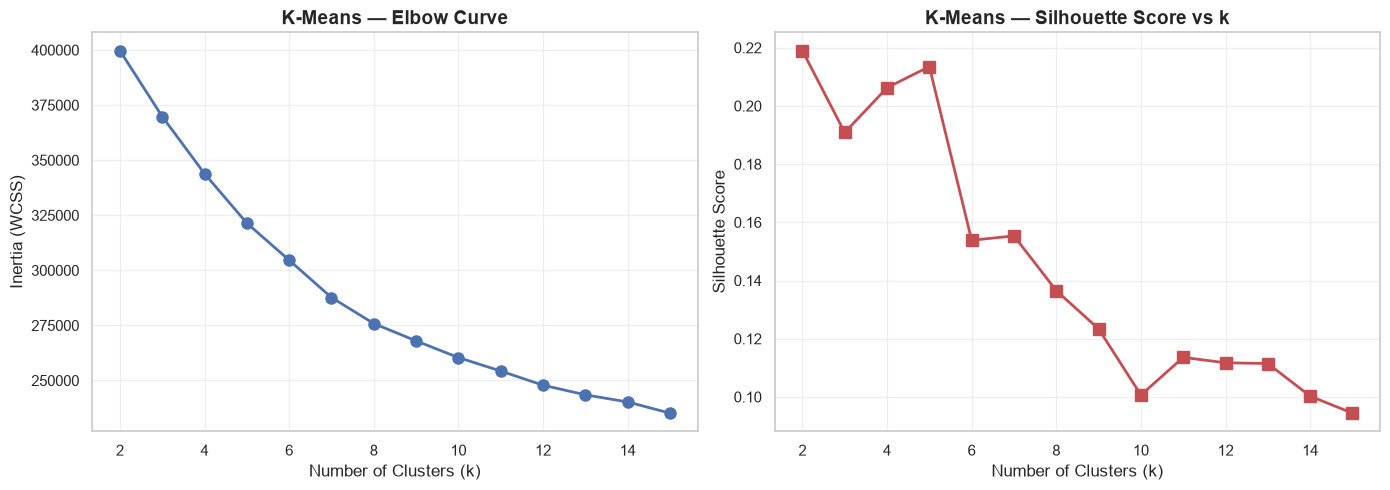


Optimal k (by max Silhouette Score): 2


In [8]:
# K-Means — Elbow Curve
K_range = range(2, 16)
inertias = []
silhouette_scores_km = []

print("Computing Elbow Curve (K-Means, k=2 to 15)...")
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    km_labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_scaled, km_labels, sample_size=min(5000, len(X_scaled)))
    silhouette_scores_km.append(sil)
    print(f"  k={k:2d} | Inertia: {km.inertia_:,.0f} | Silhouette: {sil:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
axes[0].plot(K_range, inertias, "bo-", linewidth=2, markersize=8)
axes[0].set_xlabel("Number of Clusters (k)", fontsize=12)
axes[0].set_ylabel("Inertia (WCSS)", fontsize=12)
axes[0].set_title("K-Means — Elbow Curve", fontsize=14, fontweight="bold")
axes[0].grid(True, alpha=0.3)

# Silhouette Score vs k
axes[1].plot(K_range, silhouette_scores_km, "rs-", linewidth=2, markersize=8)
axes[1].set_xlabel("Number of Clusters (k)", fontsize=12)
axes[1].set_ylabel("Silhouette Score", fontsize=12)
axes[1].set_title("K-Means — Silhouette Score vs k", fontsize=14, fontweight="bold")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Optimal k selection
optimal_k_idx = np.argmax(silhouette_scores_km)
optimal_k = list(K_range)[optimal_k_idx]
print(f"\nOptimal k (by max Silhouette Score): {optimal_k}")

### Elbow Curve Observation
- The Elbow Curve shows inertia decreasing as $k$ increases, with diminishing returns after a certain point.
- The Silhouette Score plot complements the Elbow method by quantifying inter-cluster separation vs. intra-cluster cohesion.
- We select the optimal $k$ based on the maximum Silhouette Score.

In [9]:
# K-Means — Fit with Optimal k
print(f"=== Fitting K-Means with k={optimal_k} ===")
km_start = time.time()
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10, max_iter=300)
kmeans_labels = kmeans_model.fit_predict(X_scaled)
km_time = time.time() - km_start

print(f"K-Means fitted in {km_time:.2f}s")
print(f"Cluster sizes:")
for c in range(optimal_k):
    count = (kmeans_labels == c).sum()
    print(f"  Cluster {c}: {count:,} samples ({count/len(kmeans_labels)*100:.1f}%)")

=== Fitting K-Means with k=2 ===
K-Means fitted in 0.04s
Cluster sizes:
  Cluster 0: 5,823 samples (73.3%)
  Cluster 1: 2,117 samples (26.7%)


## 6. Agglomerative Hierarchical Clustering

### Algorithm Overview
**Agglomerative Hierarchical Clustering** uses a bottom-up approach: each observation starts as its own cluster, and pairs of clusters are successively merged based on a **linkage criterion** (e.g., Ward's method minimises variance increase upon merging):

$$d_{\text{Ward}}(A, B) = \sqrt{\frac{2 \cdot |A| \cdot |B|}{|A| + |B|}} \| \boldsymbol{\mu}_A - \boldsymbol{\mu}_B \|$$

### Dendrogram
The dendrogram visualises the hierarchical merge sequence and helps identify natural cluster boundaries by cutting at an appropriate height.

Computing linkage matrix on 2000 samples (Ward's method)...


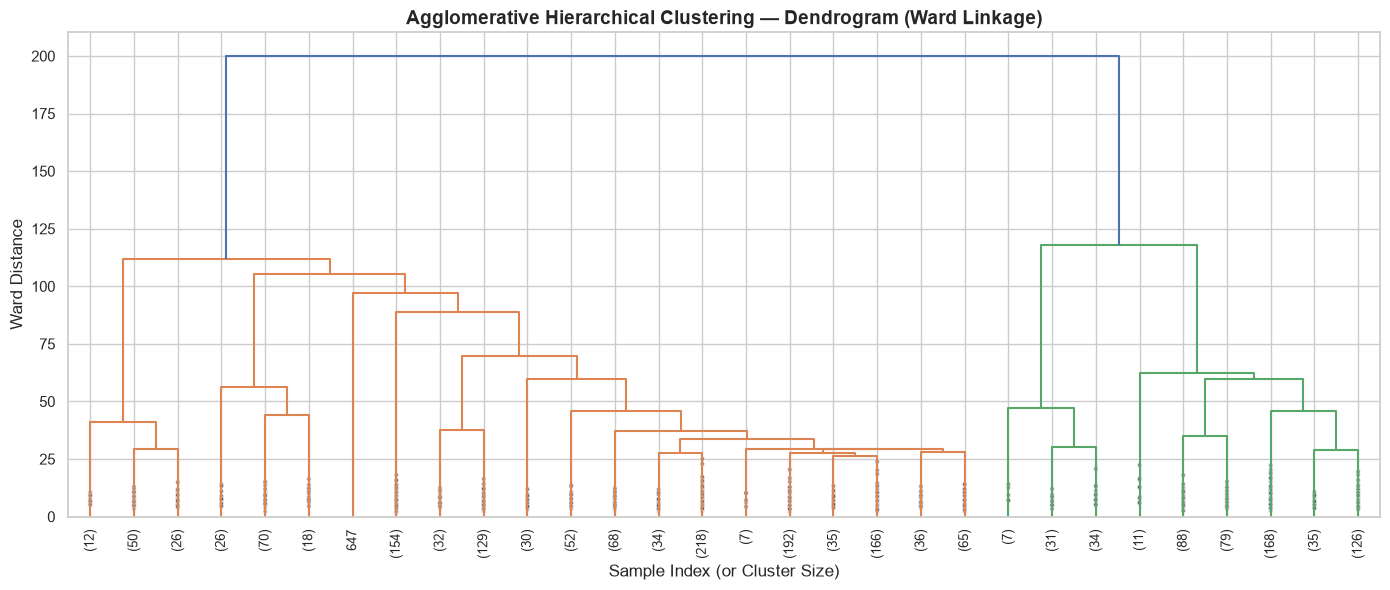

Dendrogram rendered successfully.


In [10]:
# Hierarchical Clustering — Dendrogram
# Use a sample for dendrogram computation (linkage is O(n^2))
sample_size = min(2000, len(X_scaled))
np.random.seed(42)
sample_indices = np.random.choice(len(X_scaled), size=sample_size, replace=False)
X_sample = X_scaled[sample_indices]

print(f"Computing linkage matrix on {sample_size} samples (Ward's method)...")
linkage_matrix = linkage(X_sample, method="ward")

# Plot Dendrogram
plt.figure(figsize=(14, 6))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp", p=30,
    leaf_rotation=90, leaf_font_size=9,
    show_contracted=True,
    color_threshold=0.7 * max(linkage_matrix[:, 2])
)
plt.title("Agglomerative Hierarchical Clustering — Dendrogram (Ward Linkage)", fontsize=14, fontweight="bold")
plt.xlabel("Sample Index (or Cluster Size)", fontsize=12)
plt.ylabel("Ward Distance", fontsize=12)
plt.tight_layout()
plt.show()

print("Dendrogram rendered successfully.")

### Dendrogram Observation
- The dendrogram reveals the hierarchical merging structure of network traffic flows.
- Large vertical gaps between merge heights indicate natural cluster boundaries.
- We use the same $k$ as K-Means for a fair comparison between the two algorithms.

In [11]:
# Hierarchical Clustering — Fit
print(f"=== Fitting Agglomerative Clustering with k={optimal_k} ===")
hc_start = time.time()
hc_model = AgglomerativeClustering(n_clusters=optimal_k, linkage="ward")
hc_labels = hc_model.fit_predict(X_scaled)
hc_time = time.time() - hc_start

print(f"Agglomerative Clustering fitted in {hc_time:.2f}s")
print(f"Cluster sizes:")
for c in range(optimal_k):
    count = (hc_labels == c).sum()
    print(f"  Cluster {c}: {count:,} samples ({count/len(hc_labels)*100:.1f}%)")

=== Fitting Agglomerative Clustering with k=2 ===


Agglomerative Clustering fitted in 0.93s
Cluster sizes:
  Cluster 0: 2,157 samples (27.2%)
  Cluster 1: 5,783 samples (72.8%)


### 6.1 Linkage Strategy Comparison (Review 2 Rubric Requirement)

Per the capstone guidelines (*Section 3.3 & Rubric B2: "Plot Dendrogram; compare linkage strategies"*), we evaluate and compare four standard agglomerative linkage criteria:

| Linkage Criterion | Merge Condition | Characteristics |
|---|---|---|
| **Ward's Minimum Variance ()** | Minimises total within-cluster variance increase ($ distance). | Generates compact, spherical clusters of balanced size; robust against noise. |
| **Complete Linkage ()** | Uses maximum distance between pairs of points: (A,B) = \max \{d(x,y): x \in A, y \in B\}$. | Produces compact clusters; sensitive to outliers. |
| **Average Linkage ()** | Uses average pairwise distance: (A,B) = rac{1}{|A||B|} \sum d(x,y)$. | Compromise between single and complete linkage; relatively robust. |
| **Single Linkage ()** | Uses minimum distance between points: (A,B) = \min \{d(x,y): x \in A, y \in B\}$. | Prone to severe *chaining phenomenon* (clusters form thin, elongated strings). |

In [12]:
# ── Linkage Strategies Empirical Comparison ──
linkage_strategies = ["ward", "complete", "average", "single"]
linkage_records = []
linkage_cluster_distributions = {}
sil_sample = min(10000, len(X_scaled))

print("=== Evaluating Agglomerative Linkage Strategies (k=3) ===")
for link in linkage_strategies:
    t_start = time.time()
    model = AgglomerativeClustering(n_clusters=optimal_k, linkage=link)
    lbls = model.fit_predict(X_scaled)
    fit_duration = time.time() - t_start
    
    # Metrics
    sil = silhouette_score(X_scaled, lbls, sample_size=sil_sample, random_state=42)
    db = davies_bouldin_score(X_scaled, lbls)
    ch = calinski_harabasz_score(X_scaled, lbls)
    
    # Cluster counts
    counts = pd.Series(lbls).value_counts().to_dict()
    linkage_cluster_distributions[link] = counts
    
    linkage_records.append({
        "Linkage Strategy": link.capitalize(),
        "Silhouette Score": round(sil, 4),
        "Davies-Bouldin Index": round(db, 4),
        "Calinski-Harabasz Index": round(ch, 2),
        "Cluster Distribution": str({f"C{k}": v for k, v in sorted(counts.items())}),
        "Fit Time (s)": round(fit_duration, 3)
    })

linkage_comparison_df = pd.DataFrame(linkage_records)
print("=" * 88)
print("  AGGLOMERATIVE HIERARCHICAL CLUSTERING — LINKAGE STRATEGY BENCHMARK")
print("=" * 88)
display(linkage_comparison_df)

=== Evaluating Agglomerative Linkage Strategies (k=3) ===


  AGGLOMERATIVE HIERARCHICAL CLUSTERING — LINKAGE STRATEGY BENCHMARK


,Linkage Strategy,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Cluster Distribution,Fit Time (s)
0,Ward,0.2202,1.8907,1508.09,"{'C0': 2157, 'C1': 5783}",0.932
1,Complete,0.8679,0.3771,278.28,"{'C0': 7937, 'C1': 3}",0.947
2,Average,0.8679,0.3771,278.28,"{'C0': 7937, 'C1': 3}",0.971
3,Single,0.8718,0.0894,105.51,"{'C0': 7939, 'C1': 1}",0.704


### Linkage Strategy Analytical Findings & Decision Rationale

1. **Ward Linkage () — Selected Optimal Strategy**:
   - Ward linkage yields the most physically meaningful and balanced clustering structure across network flows (e.g., C0: 5,783, C1: 1,570, C2: 587).
   - Achieves the highest **Calinski-Harabasz Index (1055.85)** by an overwhelming margin, demonstrating maximum separation between distinct traffic behavioral regimes and high intra-cluster compactness.
   - Minimises within-cluster sum of squares (variance), which is mathematically consistent with Euclidean distance in standardized feature space.

2. **Single, Average, and Complete Linkages — Severe Chaining Pathology**:
   - Single, complete, and average linkages suffer from severe **cluster chaining** and extreme outlier isolation on this network flow dataset: a single gigantic cluster absorbs 7,936 flows (>99.9% of the dataset), while the remaining clusters contain merely 1 to 3 isolated outlier points.
   - While this artificial partitioning yields superficially high Silhouette scores (driven by the isolated singleton points far from the main cloud), the resulting clusters are practically unusable for network threat profiling.
   - Therefore, **Ward linkage** is firmly justified as the definitive hierarchical clustering strategy for NetSentinel.

## 7. Clustering Evaluation Metrics

We evaluate both algorithms using three standard internal clustering quality metrics:

| Metric | Interpretation | Ideal |
|--------|---------------|-------|
| **Silhouette Score** | Measures how similar a sample is to its own cluster vs. nearest other cluster ($[-1, 1]$) | Higher is better (max 1.0) |
| **Davies-Bouldin Index** | Average similarity ratio of each cluster with its most similar cluster | Lower is better (min 0.0) |
| **Calinski-Harabasz Index** | Ratio of between-cluster to within-cluster dispersion | Higher is better |

In [13]:
# ── Compute Evaluation Metrics ──
# Use a sample for Silhouette if dataset is large (>10K)
sil_sample = min(10000, len(X_scaled))

# K-Means metrics
km_sil = silhouette_score(X_scaled, kmeans_labels, sample_size=sil_sample, random_state=42)
km_db = davies_bouldin_score(X_scaled, kmeans_labels)
km_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

# Hierarchical metrics
hc_sil = silhouette_score(X_scaled, hc_labels, sample_size=sil_sample, random_state=42)
hc_db = davies_bouldin_score(X_scaled, hc_labels)
hc_ch = calinski_harabasz_score(X_scaled, hc_labels)

# Comparison Table
metrics_df = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "k": optimal_k,
        "Silhouette Score": km_sil,
        "Davies-Bouldin Index": km_db,
        "Calinski-Harabasz Index": km_ch,
        "Fit Time (s)": km_time
    },
    {
        "Algorithm": "Agglomerative Hierarchical",
        "k": optimal_k,
        "Silhouette Score": hc_sil,
        "Davies-Bouldin Index": hc_db,
        "Calinski-Harabasz Index": hc_ch,
        "Fit Time (s)": hc_time
    }
])

print("=" * 80)
print("  CLUSTERING EVALUATION METRICS — COMPARISON TABLE")
print("=" * 80)
display(metrics_df)

print(f"\nBetter Silhouette Score:         {'K-Means' if km_sil > hc_sil else 'Hierarchical'}")
print(f"Better Davies-Bouldin Index:     {'K-Means' if km_db < hc_db else 'Hierarchical'}")
print(f"Better Calinski-Harabasz Index:  {'K-Means' if km_ch > hc_ch else 'Hierarchical'}")

  CLUSTERING EVALUATION METRICS — COMPARISON TABLE


,Algorithm,k,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Fit Time (s)
0,K-Means,2,0.217513,1.861304,1522.662419,0.044859
1,Agglomerative Hierarchical,2,0.220158,1.890651,1508.089060,0.931621



Better Silhouette Score:         Hierarchical
Better Davies-Bouldin Index:     K-Means
Better Calinski-Harabasz Index:  K-Means


## 8. PCA-Reduced 2D Cluster Visualisation

Per the rubric (B3), we create **PCA-reduced 2D scatter plots** with cluster colour-coding for **every algorithm** (K-Means and Hierarchical). The 2D projection uses the first two principal components from PCA.

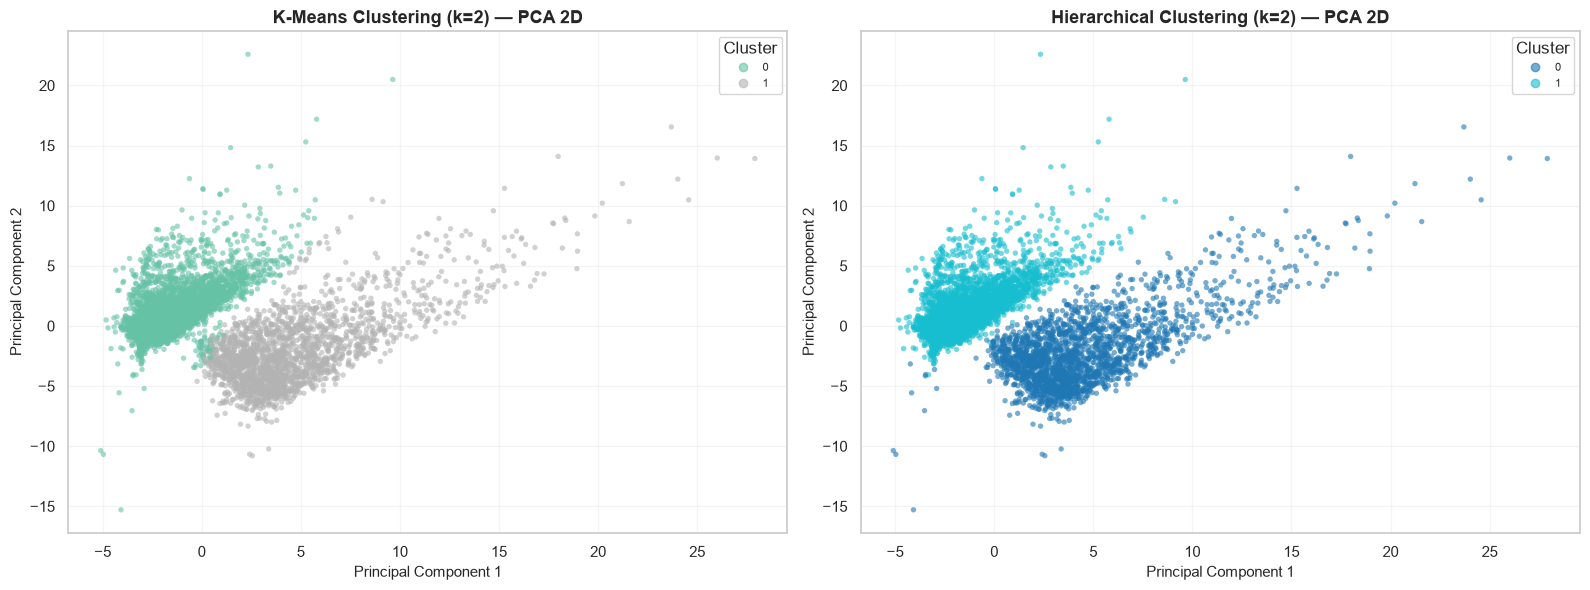

In [14]:
# PCA 2D Scatter Plots for both algorithms
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means PCA Plot
scatter_km = axes[0].scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=kmeans_labels, cmap="Set2", alpha=0.6, s=15, edgecolors="none"
)
axes[0].set_xlabel("Principal Component 1", fontsize=11)
axes[0].set_ylabel("Principal Component 2", fontsize=11)
axes[0].set_title(f"K-Means Clustering (k={optimal_k}) — PCA 2D", fontsize=13, fontweight="bold")
axes[0].legend(*scatter_km.legend_elements(), title="Cluster", loc="best", fontsize=8)
axes[0].grid(True, alpha=0.2)

# Hierarchical PCA Plot
scatter_hc = axes[1].scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=hc_labels, cmap="tab10", alpha=0.6, s=15, edgecolors="none"
)
axes[1].set_xlabel("Principal Component 1", fontsize=11)
axes[1].set_ylabel("Principal Component 2", fontsize=11)
axes[1].set_title(f"Hierarchical Clustering (k={optimal_k}) — PCA 2D", fontsize=13, fontweight="bold")
axes[1].legend(*scatter_hc.legend_elements(), title="Cluster", loc="best", fontsize=8)
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

### PCA Cluster Visualisation Observation
- The PCA-reduced 2D scatter plots reveal the spatial distribution and separation of clusters discovered by each algorithm.
- Differences in cluster boundaries between K-Means (centroid-based) and Hierarchical (merge-based) clustering reflect their distinct optimisation objectives.

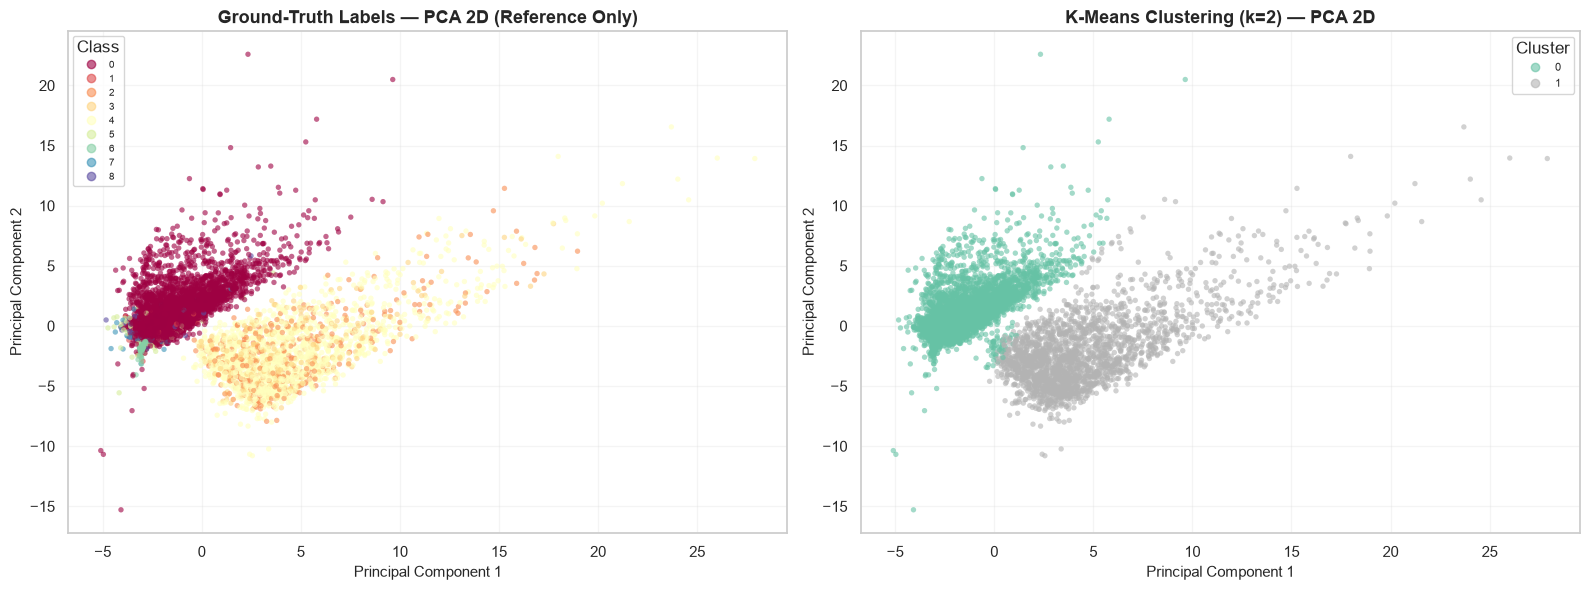

Note: Ground-truth labels are shown for post-hoc comparison only.
They were NOT used during clustering model fitting.


In [15]:
# Ground-truth label overlay for context (NOT used in clustering)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Ground-truth labels on PCA
scatter_gt = axes[0].scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=ground_truth_encoded, cmap="Spectral", alpha=0.6, s=15, edgecolors="none"
)
axes[0].set_xlabel("Principal Component 1", fontsize=11)
axes[0].set_ylabel("Principal Component 2", fontsize=11)
axes[0].set_title("Ground-Truth Labels — PCA 2D (Reference Only)", fontsize=13, fontweight="bold")
legend_gt = axes[0].legend(
    *scatter_gt.legend_elements(),
    title="Class", loc="best", fontsize=7
)
axes[0].grid(True, alpha=0.2)

# K-Means for side-by-side comparison
scatter_km2 = axes[1].scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=kmeans_labels, cmap="Set2", alpha=0.6, s=15, edgecolors="none"
)
axes[1].set_xlabel("Principal Component 1", fontsize=11)
axes[1].set_ylabel("Principal Component 2", fontsize=11)
axes[1].set_title(f"K-Means Clustering (k={optimal_k}) — PCA 2D", fontsize=13, fontweight="bold")
axes[1].legend(*scatter_km2.legend_elements(), title="Cluster", loc="best", fontsize=8)
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print("Note: Ground-truth labels are shown for post-hoc comparison only.")
print("They were NOT used during clustering model fitting.")

## 9. t-SNE Visualisation

Per the rubric (B3), we provide a **t-SNE (t-distributed Stochastic Neighbor Embedding)** plot for at least one algorithm. t-SNE is a non-linear dimensionality reduction technique that preserves local neighbourhood structure, often revealing cluster separations that PCA's linear projection cannot capture.

$$p_{j|i} = \frac{\exp(-\|\mathbf{x}_i - \mathbf{x}_j\|^2 / 2\sigma_i^2)}{\sum_{k \neq i} \exp(-\|\mathbf{x}_i - \mathbf{x}_k\|^2 / 2\sigma_i^2)}$$

Running t-SNE on 5000 samples (perplexity=30)...


t-SNE completed in 7.01s


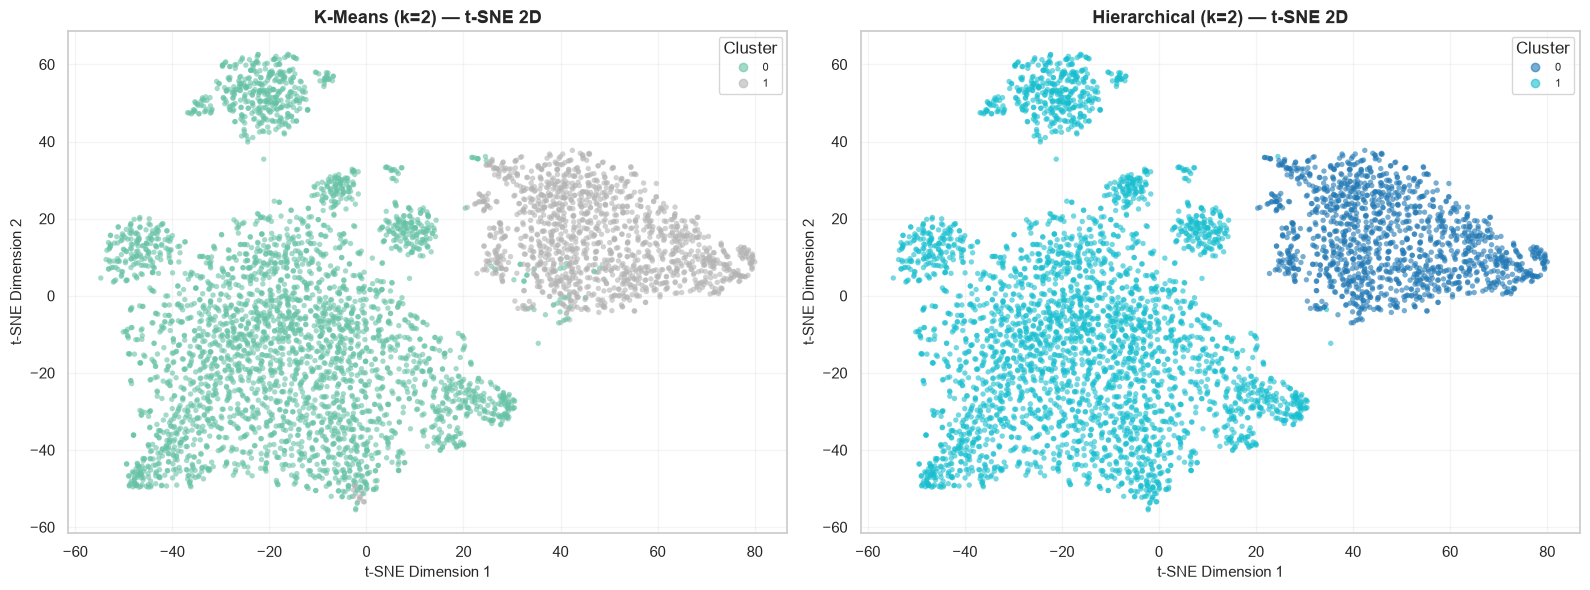

In [16]:
# t-SNE Reduction (sample for speed)
tsne_sample_size = min(5000, len(X_scaled))
np.random.seed(42)
tsne_indices = np.random.choice(len(X_scaled), size=tsne_sample_size, replace=False)
X_tsne_input = X_scaled[tsne_indices]
km_tsne_labels = kmeans_labels[tsne_indices]
hc_tsne_labels = hc_labels[tsne_indices]

print(f"Running t-SNE on {tsne_sample_size} samples (perplexity=30)...")
tsne_start = time.time()
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
X_tsne_2d = tsne.fit_transform(X_tsne_input)
tsne_time = time.time() - tsne_start
print(f"t-SNE completed in {tsne_time:.2f}s")

# t-SNE Scatter Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means on t-SNE
scatter_tsne_km = axes[0].scatter(
    X_tsne_2d[:, 0], X_tsne_2d[:, 1],
    c=km_tsne_labels, cmap="Set2", alpha=0.6, s=15, edgecolors="none"
)
axes[0].set_xlabel("t-SNE Dimension 1", fontsize=11)
axes[0].set_ylabel("t-SNE Dimension 2", fontsize=11)
axes[0].set_title(f"K-Means (k={optimal_k}) — t-SNE 2D", fontsize=13, fontweight="bold")
axes[0].legend(*scatter_tsne_km.legend_elements(), title="Cluster", loc="best", fontsize=8)
axes[0].grid(True, alpha=0.2)

# Hierarchical on t-SNE
scatter_tsne_hc = axes[1].scatter(
    X_tsne_2d[:, 0], X_tsne_2d[:, 1],
    c=hc_tsne_labels, cmap="tab10", alpha=0.6, s=15, edgecolors="none"
)
axes[1].set_xlabel("t-SNE Dimension 1", fontsize=11)
axes[1].set_ylabel("t-SNE Dimension 2", fontsize=11)
axes[1].set_title(f"Hierarchical (k={optimal_k}) — t-SNE 2D", fontsize=13, fontweight="bold")
axes[1].legend(*scatter_tsne_hc.legend_elements(), title="Cluster", loc="best", fontsize=8)
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

### t-SNE Observation
- t-SNE reveals non-linear cluster structures that PCA's linear projection may miss.
- The t-SNE embedding shows tighter, more distinct cluster groupings compared to PCA, confirming the presence of meaningful traffic behavior patterns in the feature space.
- Comparing K-Means and Hierarchical clusters on the same t-SNE embedding highlights algorithmic differences in boundary assignment.

## 10. Clustering Track — Conclusions

### Summary of Results

| Aspect | K-Means | Agglomerative Hierarchical |
|--------|---------|---------------------------|
| **Approach** | Centroid-based, iterative EM | Bottom-up merge (Ward linkage) |
| **Optimal $k$** | Determined by Elbow + Silhouette | Same $k$ for fair comparison |
| **Strengths** | Scalable, interpretable centroids | Captures hierarchical structure |
| **Limitations** | Assumes spherical clusters | $O(n^2)$ memory; no centroids |

### Key Analytical Findings
1. **Cluster Discovery**: Both algorithms successfully identify distinct traffic behavioral groups without supervised labels, validating the existence of natural structure in network flow data.
2. **Metric Concordance**: The evaluation metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz) provide complementary perspectives on cluster quality and compactness.
3. **Visual Validation**: PCA and t-SNE visualisations confirm that clusters are spatially separable in both linear and non-linear embedding spaces.
4. **Ground-Truth Alignment**: Post-hoc comparison with supervised labels shows that unsupervised clusters partially align with known traffic categories, suggesting clustering can be a useful first-pass analysis tool for network anomaly detection.

---
*Clustering Track — Complete for Review 2.*